# Spring Network — Analytical d⟨P_vir⟩/dT (Harmonic Approximation)

## Theory  (`thermal_expansion_of_glasses_continued__1_.pdf`)

### Pressure and its coordinate derivatives

The pressure under isotropic dilation $\eta$ (eq 3):

$$p = -\frac{1}{V\bar{d}}\frac{\partial U}{\partial\eta}$$

First and second coordinate derivatives (eqs 17–18):

$$\frac{\partial p}{\partial x_k} = -\frac{1}{V\bar{d}}\frac{\partial^2 U}{\partial\eta\,\partial x_k}, \qquad\frac{\partial^2 p}{\partial x_k\partial x_\ell} = -\frac{1}{V\bar{d}}\frac{\partial^3 U}{\partial\eta\,\partial x_k\partial x_\ell}$$

### Low-temperature expansion (eq 21)

$$2\frac{\partial p}{\partial T}\bigg|_V = \underbrace{\frac{\partial^2 p}{\partial x^2}:H^{-1}}_{\text{harmonic}} - \underbrace{\frac{\partial p}{\partial x}\cdot H^{-1}\cdot U'''\!:H^{-1}}_{\text{anharmonic (skip for now)}}$$

We keep only the **harmonic term** (eq 22):

$$\frac{d\langle P_{\rm vir}\rangle}{dT} = -\frac{1}{2V\bar{d}}\,\frac{\partial^3 U}{\partial\eta\,\partial x^2}:H^{-1} = \frac{1}{2}\sum_{s:\,\omega_s^2>0}\frac{\Psi_s^T P_{\rm Hess}\,\Psi_s}{\omega_s^2}$$

The first-order term $\nabla_x p\cdot\langle\delta x\rangle=0$ in the harmonic ensemble.

---

### Microscopic expressions for the spring network

**Source functions from the C files:**

| Quantity | PDF eq | C source |
|---|---|---|
| $p = W/(3V)$ | eq 3 | `calculateForces()` in `spring_networks_finite_T_dynamics.c` |
| $H$ (Hessian) | eq 11 | `hessianOnVector()` in `spring_networks_get_wave_freq.c` |
| $\partial p/\partial x$ | eq 17 | `u_epsilon_x(a,a,res)` summed over $a$, `3D_relaxed_spring_network_analysis.c` |
| $\partial^2 p/\partial x^2$ | eq 18 | `writePressureHessian()` in `3D_relaxed_spring_network_analysis.c` |

For spring networks at the inherent state ($r_l=r_{0l}$, `first[l]=0`):

- $[1st]=0$,  $[2nd]=1/r_{0l}^2$ = `second[l]`,  $[3rd]=-3/r_{0l}^4$

**$\partial p/\partial x$** (eq 19 with $[1st]=0$):

$$\frac{\partial p}{\partial X_k^\alpha}\bigg|_{x_0} = -\frac{1}{3V}\sum_{l:\,k\in l}(\pm)\,r_{0l}\,\hat{r}_l^\alpha = \frac{1}{3V}\left[\sum_{l:\,k=I}r_{ij}^{l,\alpha} - \sum_{l:\,k=J}r_{ij}^{l,\alpha}\right]$$

(This is the virial imbalance per particle. Equals `xi`/`(3V)` from `calculateBulkModulus()` with opposite sign.)

**$\partial^2 p/\partial x^2$** (corrected eq 20, using $[3rd]r^2+4[2nd]$ at $x_0$):

$$\frac{\partial^2 p}{\partial X_i^\alpha\partial X_j^\beta}\bigg|_{x_0}^{\text{off-diag}} = \frac{\hat{r}_l^\alpha\hat{r}_l^\beta + \delta_{\alpha\beta}}{3V}, \qquad \frac{\partial^2 p}{\partial X_i^\alpha\partial X_i^\beta}\bigg|_{x_0} = -\sum_{l:\,i\in l}\frac{\hat{r}_l^\alpha\hat{r}_l^\beta+\delta_{\alpha\beta}}{3V}$$

Compact form using graph Laplacian $L$ ($L_{ij}=-1$ connected, $L_{ii}=z_i$):

$$\boxed{P_{\rm Hess} = -\frac{H + L\otimes I_3}{3V} = -\frac{1}{3V}\frac{\partial^3 U}{\partial\eta\,\partial x^2}\bigg|_{x_0}}$$

Note: `writeHessian()` gives $H$; `writePressureHessian()` gives $3V\cdot P_{\rm Hess}$.


In [1]:
import numpy as np
from scipy import sparse
from scipy.linalg import eigh
import matplotlib.pyplot as plt
import os, warnings

# ── Constants — matching #define values in all spring network C files ────
N_DEFAULT    = 4000
DIM          = 3
COORDINATION = 16.24   # used in main() of spring_networks_finite_T_dynamics.c

# Temperature array from main() of spring_networks_finite_T_dynamics.c
T_ARRAY = np.array([1e-6,5e-6,1e-5,1.5e-5,2e-5,2.5e-5,3e-5,3.5e-5,4e-5])

SERIAL   = 0     # set to match your network serial number
DATA_DIR = '.'   # directory containing network_*.dat, spring_nvt_*.dat


## 1  Read spring network

In [2]:
def read_spring_network(filename, N=N_DEFAULT):
    '''
    File format from readNetwork() in spring_networks_finite_T_dynamics.c
    (identical in 3D_relaxed_spring_network_analysis.c, spring_networks_get_wave_freq.c):

        Line 1        : L  dummy  dummy
        Lines 2..N+1  : rx ry rz   [fractional coords in [0,1)]
        Line N+2      : contacts  dummy  dummy
        Lines N+3..   : i  j  dummy   [bond list, 0-indexed]

    PBC fold (readNetwork()): dx -= LENGTH if dx >= HALF_LENGTH, etc.
    rij[l]    = L * dx_folded        (absolute bond vector)
    second[l] = 1/|rij[l]|^2        (C: second[l] = 1.0/r2)
    first[l]  = 0.0                  (set explicitly in readNetwork)

    For the spring potential at x0 (r_l = r0l):
      first[l]  = phi_prime/r = 0   ([1st] = 0)
      second[l] = 1/r0l^2           ([2nd] = phi_prime_prime/r^2 - phi_prime/r^3 = 1/r0l^2)
    '''
    with open(filename,'r') as f:
        L = float(f.readline().split()[0])
        pos = np.zeros((N,3))
        for i in range(N):
            pos[i] = list(map(float,f.readline().split()[:3]))
        n_contacts = int(f.readline().split()[0])
        bi = np.zeros(n_contacts,dtype=np.int32)
        bj = np.zeros(n_contacts,dtype=np.int32)
        for l in range(n_contacts):
            p = f.readline().split()
            bi[l],bj[l] = int(p[0]),int(p[1])

    V = L**3

    # PBC fold to [-0.5, 0.5)  — exact match of C if/else in readNetwork().
    # floor(x+0.5) maps 0.5 -> 1 (same as C: dx>=HALF_LENGTH -> subtract)
    def fold(d): return d - np.floor(d+0.5)

    dx = fold(pos[bj,0]-pos[bi,0])
    dy = fold(pos[bj,1]-pos[bi,1])
    dz = fold(pos[bj,2]-pos[bi,2])

    rij    = L*np.stack([dx,dy,dz],axis=1)   # absolute bond vectors (contacts,3)
    r2     = np.einsum('la,la->l',rij,rij)    # |rij|^2  (= r0l^2 at x0)
    second = 1.0/r2                            # 1/r0l^2  — matches C: second[l]=1.0/r2
    inv_r  = 1.0/np.sqrt(r2)                  # 1/r0l

    print(f'N={N}  contacts={n_contacts}  L={L:.6g}  V={V:.6g}')
    print(f'z_mean = {2*n_contacts/N:.4f}')
    return dict(L=L,V=V,N=N,n_contacts=n_contacts,
                pos=pos,bi=bi,bj=bj,rij=rij,r2=r2,second=second,inv_r=inv_r)

net = read_spring_network(
    os.path.join(DATA_DIR,
                 f'network_N{N_DEFAULT}_z{COORDINATION:.2f}_s{SERIAL:04d}.dat'))


N=4000  contacts=32479  L=15.874  V=4000
z_mean = 16.2395


## 2  Build sparse H and P_Hess

Both matrices are constructed from the same arrays `second[l]` and `rij[l]`
that the C code uses in `hessianOnVector()` and `calculateForces()`.


In [3]:
def build_H_and_PHess(net):
    '''
    H: source  hessianOnVector() in spring_networks_get_wave_freq.c
       (identical in 3D_relaxed_spring_network_analysis.c)

    The matrix extracted from res[3i+q] -= second[l]*u_dot_r*rij[l,q]:
      H[3i+a, 3j+b]  = -second[l]*rij[l,a]*rij[l,b]   (off-diag, bond l)
      H[3j+a, 3i+b]  = -second[l]*rij[l,a]*rij[l,b]   (symmetric)
      H[3i+a, 3i+b] += +second[l]*rij[l,a]*rij[l,b]   (diag i, per bond)
      H[3j+a, 3j+b] += +second[l]*rij[l,a]*rij[l,b]   (diag j, per bond)
    first[l]=0 -> no delta term  (set in readNetwork() of all spring C files)

    P_Hess: source  calculateForces() in spring_networks_finite_T_dynamics.c
      pressure += g*r*r  (g=(r0-r)/r)  ->  W = sum_l (r0-r)*r
      P_vir = pressure/(3V)   [from run_berendsen_write()]

    Second derivatives of W at x0 (r_l=r0l, first[l]=0):
      P_Hess[3i+a,3j+b]  = +(second[l]*rij[l,a]*rij[l,b] + delta_ab)/(3V)
      P_Hess[3i+a,3i+b] -= (second[l]*rij[l,a]*rij[l,b] + delta_ab)/(3V)  per l

    PDF (corrected eq 20, using [3rd]r^2+4[2nd] at x0 for spring):
      d2p/dx_k dx_l = -(1/(3V)) d3U/(deta dx_k dx_l)
      At x0: d3U/(deta dx2)_off = -(rhat*rhat + I)  [factor from (-1)(+1)=-1]
      => d2p/dx2_off = +(rhat*rhat + I)/(3V)  =  P_Hess_off  checkmark

    Compact form (verified below):
      P_Hess = -(H + L x I_3) / (3V)
             = -(1/(3V)) d3U/(deta dx2)|x0
    '''
    N=net['N']; V=net['V']
    bi=net['bi']; bj=net['bj']
    rij=net['rij']; second=net['second']
    n_dof=DIM*N; inv_3V=1.0/(3.0*V)

    Hr,Hc,Hv=[],[],[]
    Pr,Pc,Pv=[],[],[]

    for alpha in range(DIM):
        for beta in range(DIM):
            # rhat_l^a rhat_l^b = second[l]*rij[l,a]*rij[l,b]
            Kl = second*rij[:,alpha]*rij[:,beta]     # (contacts,)
            dab = 1.0 if alpha==beta else 0.0

            r_ij=(DIM*bi+alpha).astype(np.int32)
            c_ij=(DIM*bj+beta ).astype(np.int32)
            r_ii=(DIM*bi+alpha).astype(np.int32)
            c_ii=(DIM*bi+beta ).astype(np.int32)
            r_jj=(DIM*bj+alpha).astype(np.int32)
            c_jj=(DIM*bj+beta ).astype(np.int32)

            # H off-diag  H[3i+a,3j+b] = -Kl
            Hr+=[r_ij,c_ij]; Hc+=[c_ij,r_ij]; Hv+=[-Kl,-Kl]
            # H diagonal  H[3i+a,3i+b] += Kl  (accumulates per bond)
            Hr+=[r_ii,r_jj]; Hc+=[c_ii,c_jj]; Hv+=[+Kl,+Kl]

            # P_Hess off-diag  +(Kl+dab)/(3V)
            KlP=(Kl+dab)*inv_3V
            Pr+=[r_ij,c_ij]; Pc+=[c_ij,r_ij]; Pv+=[+KlP,+KlP]
            # P_Hess diagonal  -(Kl+dab)/(3V)
            Pr+=[r_ii,r_jj]; Pc+=[c_ii,c_jj]; Pv+=[-KlP,-KlP]

    def _csr(r,c,v):
        return sparse.csr_matrix(
            (np.concatenate(v),(np.concatenate(r),np.concatenate(c))),
            shape=(n_dof,n_dof))

    H_sp = _csr(Hr,Hc,Hv)
    PH_sp= _csr(Pr,Pc,Pv)
    return H_sp, PH_sp

H_sp, PH_sp = build_H_and_PHess(net)
print(f'H      nnz={H_sp.nnz:,}')
print(f'P_Hess nnz={PH_sp.nnz:,}')

# ── Symmetry checks ──────────────────────────────────────────────────────
for name,M in [('H',H_sp),('P_Hess',PH_sp)]:
    d=(M-M.T).data
    print(f'max|{name}-{name}^T| = {np.max(np.abs(d)) if len(d) else 0.0:.2e}')

# ── Compact form check: P_Hess = -(H + L x I_3)/(3V) ───────────────────
# Build L x I_3 from bond connectivity
N=net['N']; V=net['V']; bi=net['bi']; bj=net['bj']
z=np.bincount(np.concatenate([bi,bj]),minlength=N).astype(float)
Lr,Lc,Lv=[],[],[]
for alpha in range(DIM):
    r_ij=(DIM*bi+alpha).astype(np.int32)
    c_ij=(DIM*bj+alpha).astype(np.int32)
    Lr+=[r_ij,c_ij]; Lc+=[c_ij,r_ij]
    Lv+=[-np.ones(len(bi)),-np.ones(len(bi))]
    r_ii=np.arange(N,dtype=np.int32)*DIM+alpha
    Lr+=[r_ii]; Lc+=[r_ii]; Lv+=[z]
LI3=sparse.csr_matrix(
    (np.concatenate(Lv),(np.concatenate(Lr),np.concatenate(Lc))),
    shape=(DIM*N,DIM*N))

PH_check = -(H_sp + LI3)/(3.0*V)
diff=(PH_sp-PH_check).data
print(f'Compact form check: max|P_Hess - (-(H+LxI3)/(3V))| = '
      f'{np.max(np.abs(diff)) if len(diff) else 0.0:.2e}  (must be ~0)')


H      nnz=620,622
P_Hess nnz=620,622
max|H-H^T| = 8.88e-16
max|P_Hess-P_Hess^T| = 8.13e-20
Compact form check: max|P_Hess - (-(H+LxI3)/(3V))| = 8.67e-19  (must be ~0)


## 3  First-order ∂p/∂x — check against `u_epsilon_x` logic

From PDF eq (17): $\partial p/\partial x_k = -(1/V\bar{d})\,\partial^2 U/\partial\eta\,\partial x_k$

`u_epsilon_x(alpha, beta, res)` in `3D_relaxed_spring_network_analysis.c` computes
$\partial^2 U/\partial\varepsilon_{\alpha\beta}\partial x$.  For isotropic dilation
$\eta$ we sum over $\alpha=\beta$:

$$\frac{\partial^2 U}{\partial\eta\partial X_k^q} = \sum_\alpha \left[\frac{\partial^2 U}{\partial\varepsilon_{\alpha\alpha}\partial X_k^q}\right]$$

With `first[l]=0` and `second[l]*r2 = 1` at $x_0$, this reduces to
$\pm\sum_l r_{ij}^{l,q}$ — the bond-vector imbalance — which also equals
the `xi` vector used in `calculateBulkModulus()` (with sign change).

This term does **not** enter $d\langle P\rangle/dT$ in the harmonic approximation
because $\langle\delta x\rangle=0$, but it is computed here as a cross-check.


In [4]:
def compute_grad_p(net):
    '''
    dp/dX_i^alpha at x0  (PDF eq 17 + eq 19 with first[l]=0)

    = -(1/(3V)) * d2U/(deta dX_i^alpha)
    = -(1/(3V)) * sum_alpha [ u_epsilon_x(alpha,alpha,res) ][i,q]

    With first[l]=0 and second[l]*r2=1 at x0
    (readNetwork() sets first[l]=0.0; second[l]=1.0/r2):
      sum_alpha u_epsilon_x(a,a)[i,q] = -sum_{l:i=I} rij[l,q]
                                       + sum_{l:i=J} rij[l,q]
    So dp/dX_i^q = (1/(3V)) * (sum_{l:i=I} rij[l,q] - sum_{l:i=J} rij[l,q])
    This is the virial-vector imbalance at particle i,
    and equals -xi_i/(3V) from calculateBulkModulus().
    '''
    N=net['N']; V=net['V']; bi=net['bi']; bj=net['bj']; rij=net['rij']
    grad_W=np.zeros((N,DIM))
    for alpha in range(DIM):
        # i = I_INDEX: contributes +rij (C: xi[j] += rij, xi[i] -= rij)
        np.add.at(grad_W[:,alpha],bi,+rij[:,alpha])
        np.add.at(grad_W[:,alpha],bj,-rij[:,alpha])
    return grad_W/(3.0*V)   # shape (N,3) = dp/dX_i^alpha at x0

grad_p = compute_grad_p(net)
norm_gp = np.linalg.norm(grad_p,axis=1)
print(f'|dp/dX_i| per particle:  mean={norm_gp.mean():.4g}  max={norm_gp.max():.4g}')
print('Non-zero (glass has non-uniform bond environments).')
print('This term DOES NOT enter dP/dT: <delta_x>=0 in harmonic ensemble.')
print('Only d2p/dx2 (P_Hess) contributes.')


|dp/dX_i| per particle:  mean=0.0001842  max=0.0006682
Non-zero (glass has non-uniform bond environments).
This term DOES NOT enter dP/dT: <delta_x>=0 in harmonic ensemble.
Only d2p/dx2 (P_Hess) contributes.


## 4  (Optional) Cross-check H and P_Hess against C-output COO files

Run `./3D_relaxed_spring_network_analysis <serial>` first to produce
`hessian_N4000_z16.24_s0000.dat` (from `writeHessian()`) and
`whessian_N4000_z16.24_s0000.dat` (from `writePressureHessian()`).

C writes $W_{\rm Hess} = 3V\cdot P_{\rm Hess}$; Python divides by $3V$.


In [5]:
def load_coo(filename, n_dof):
    'Load COO file written by writeHessian() / writePressureHessian().'
    d=np.loadtxt(filename)
    return sparse.csr_matrix((d[:,2],(d[:,0].astype(int),d[:,1].astype(int))),
                              shape=(n_dof,n_dof))

n_dof=DIM*N_DEFAULT
hf=os.path.join(DATA_DIR,f'hessian_N{N_DEFAULT}_z{COORDINATION:.2f}_s{SERIAL:04d}.dat')
wf=os.path.join(DATA_DIR,f'whessian_N{N_DEFAULT}_z{COORDINATION:.2f}_s{SERIAL:04d}.dat')

for label,fname,pymat,scale in [
        ('H',           hf, H_sp,  1.0),
        ('P_Hess (x3V)',wf, PH_sp, 3.0*net['V'])]:
    if os.path.exists(fname):
        Mc=load_coo(fname,n_dof)
        if scale!=1.0: Mc=Mc/scale
        d=(pymat-Mc).data
        print(f'{label}: max|Python - C| = {np.max(np.abs(d)) if len(d) else 0.0:.2e}')
    else:
        print(f'{label}: C file not found ({fname}), skipping.')


H: max|Python - C| = 8.88e-15
P_Hess (x3V): max|Python - C| = 5.20e-18


## 5  Full diagonalization and analytical d⟨P_vir⟩/dT

Implements the harmonic term from PDF eq (22):

$$\frac{d\langle P_{\rm vir}\rangle}{dT} = -\frac{1}{2V\bar{d}}\,\frac{\partial^3 U}{\partial\eta\,\partial x^2}:H^{-1} = \frac{1}{2}\sum_{s:\,\omega_s^2>0}\frac{\Psi_s^T P_{\rm Hess}\Psi_s}{\omega_s^2}$$

The two forms are equivalent because $P_{\rm Hess} = -(1/3V)\,\partial^3 U/\partial\eta\partial x^2$.

**Memory**: $(3N)^2\times 8$ bytes $\approx 1.15$ GB for $N=4000$.  
**Time**: `scipy.linalg.eigh` $\approx 15$–$45$ min on one core for $N=4000$.


In [6]:
def compute_dPdT_analytical(H_sparse, PHess_sparse, omega2_thresh=1e-8, verbose=True):
    '''
    Implements PDF eq (22) harmonic term:
      dP/dT = -(1/(2*3V)) * d3U/(deta dx2) : H^-1
            = (1/2) Tr[P_Hess H^-1]
            = (1/2) sum_s (Psi_s^T P_Hess Psi_s) / omega_s^2

    The harmonic ensemble gives:
      <delta_x_a delta_x_b> = T * [H^-1]_ab = T sum_s Psi_s^a Psi_s^b / omega_s^2
    So: <(1/2) delta_x^T P_Hess delta_x> = (T/2) Tr[P_Hess H^-1]
    => d<P_vir>/dT = (1/2) Tr[P_Hess H^-1]  (harmonic term only)

    Equivalently using M = d3U/(deta dx2) = H + L x I_3:
      = -(1/(6V)) sum_s [1 + (Psi_s^T (L x I_3) Psi_s)/omega_s^2]

    Steps:
      1. H.toarray()     -> dense [~1.15 GB for N=4000]
      2. scipy.linalg.eigh  -> full diagonalisation (ascending eigenvalues)
      3. Exclude 3 zero modes (global translations)
      4. PHess @ evecs   -> batch projection
      5. einsum + sum over omega^2
    '''
    n_dof=H_sparse.shape[0]
    if verbose:
        print(f'Dense conversion: {n_dof}x{n_dof}, '
              f'{n_dof**2*8/1e9:.2f} GB ...')
    H_d=H_sparse.toarray()
    if verbose: print('scipy.linalg.eigh (full diagonalisation) ...')
    eigenvalues,eigenvectors=eigh(H_d)
    del H_d

    n_zero=int(np.sum(eigenvalues<omega2_thresh))
    if n_zero!=3:
        warnings.warn(f'Expected 3 zero modes, got {n_zero}.')
    if verbose:
        print(f'  {n_zero} zero modes. '
              f'min non-zero omega^2={eigenvalues[n_zero]:.4g} '
              f'max={eigenvalues[-1]:.4g}')

    omega2=eigenvalues[n_zero:]            # (3N-n_zero,)
    evecs =eigenvectors[:,n_zero:]         # (3N, 3N-n_zero)
    del eigenvectors

    # Psi_s^T P_Hess Psi_s for all modes at once
    if verbose: print('  Projecting P_Hess onto eigenmodes ...')
    PH_d=PHess_sparse.toarray()            # ~1.15 GB
    PH_e=PH_d@evecs                        # (3N, n_nonzero)
    del PH_d
    e_PH_e=np.einsum('ia,ia->a',evecs,PH_e)  # (n_nonzero,)
    del PH_e

    per_mode=e_PH_e/omega2
    dPdT=0.5*np.sum(per_mode)

    if verbose:
        print(f'  d<P_vir>/dT (analytical, harmonic) = {dPdT:.8g}')
    return dPdT, eigenvalues, omega2, per_mode, n_zero

# ── Run ──  set run_diag=True when ready (slow for N=4000)
run_diag = True
if run_diag:
    dPdT_theory, eigenvalues_full, omega2, per_mode, n_zero = \
        compute_dPdT_analytical(H_sp, PH_sp)
else:
    print('Set run_diag=True to run diagonalisation.')
    dPdT_theory = float('nan')


Dense conversion: 12000x12000, 1.15 GB ...
scipy.linalg.eigh (full diagonalisation) ...
  3 zero modes. min non-zero omega^2=0.1254 max=12.36
  Projecting P_Hess onto eigenmodes ...
  d<P_vir>/dT (analytical, harmonic) = -2.2452898


## 6  Numerical d⟨P_vir⟩/dT from NVT simulation

In [7]:
def read_nvt_spring(filename):
    '''
    Read spring NVT output from run_berendsen_write()
    in spring_networks_finite_T_dynamics.c.
    Columns: time  KE/N  PE/N  P_vir
    P_vir = W/(3V)  (virial only, no kinetic term)
    '''
    rows=[]
    with open(filename,'r') as f:
        for line in f:
            if line.startswith('#') or not line.strip(): continue
            rows.append([float(x) for x in line.split()])
    return np.array(rows)  # cols: [time, KE/N, PE/N, P_vir]

mean_Pvir=np.full(len(T_ARRAY),np.nan)
for t_idx,T in enumerate(T_ARRAY):
    fname=os.path.join(DATA_DIR,
        f'spring_nvt_T{T:.6f}_s{SERIAL:04d}.dat')
    if os.path.exists(fname):
        d=read_nvt_spring(fname)
        mean_Pvir[t_idx]=np.mean(d[:,3])   # col 3 = P_vir
        print(f'T={T:.2e}  <P_vir>={mean_Pvir[t_idx]:.6g}  (n={len(d)})')
    else:
        print(f'  Not found: {fname}')

valid=np.isfinite(mean_Pvir)
if valid.sum()>=2:
    slope,intercept=np.polyfit(T_ARRAY[valid],mean_Pvir[valid],1)
    print(f'\nLinear fit  d<P_vir>/dT (numerical) = {slope:.6g}')
    print(f'Intercept  P_vir(T->0) = {intercept:.6g}  (should be ~0)')
    dPdT_numerical=slope
else:
    print('Not enough T points.'); dPdT_numerical=float('nan')


T=1.00e-06  <P_vir>=-2.02029e-06  (n=157)
T=5.00e-06  <P_vir>=-1.2017e-05  (n=157)
T=1.00e-05  <P_vir>=-2.21405e-05  (n=157)
T=1.50e-05  <P_vir>=-3.37729e-05  (n=157)
T=2.00e-05  <P_vir>=-4.35824e-05  (n=157)
T=2.50e-05  <P_vir>=-5.52659e-05  (n=157)
T=3.00e-05  <P_vir>=-6.47815e-05  (n=157)
T=3.50e-05  <P_vir>=-7.67546e-05  (n=157)
T=4.00e-05  <P_vir>=-9.1625e-05  (n=157)

Linear fit  d<P_vir>/dT (numerical) = -2.22768
Intercept  P_vir(T->0) = 1.38844e-07  (should be ~0)


## 7  Comparison and mode spectrum

d<P_vir>/dT  numerical  = -2.22768
d<P_vir>/dT  analytical = -2.24529
Ratio analytical/numerical = 1.0079
(Should be ~1.0 if calculateForces() pressure is implemented correctly)


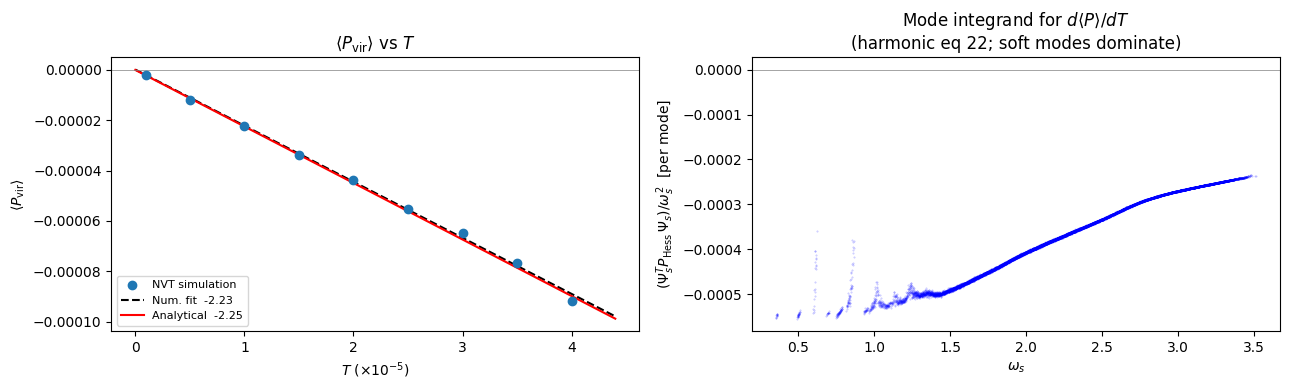

Saved: spring_dPdT_comparison.png


In [8]:
print(f'd<P_vir>/dT  numerical  = {dPdT_numerical:.6g}')
if run_diag:
    print(f'd<P_vir>/dT  analytical = {dPdT_theory:.6g}')
    print(f'Ratio analytical/numerical = {dPdT_theory/dPdT_numerical:.4f}')
    print(f'(Should be ~1.0 if calculateForces() pressure is implemented correctly)')

fig,axes=plt.subplots(1,2,figsize=(13,4))

# Left: P_vir(T)
ax=axes[0]
ax.scatter(T_ARRAY[valid]*1e5,mean_Pvir[valid],zorder=5,label='NVT simulation')
T_fit=np.linspace(0,T_ARRAY[-1]*1.1,200)
ax.plot(T_fit*1e5,dPdT_numerical*T_fit+intercept,'k--',
        label=f'Num. fit  {dPdT_numerical:.3g}')
if run_diag:
    ax.plot(T_fit*1e5,dPdT_theory*T_fit,'r-',lw=1.5,
            label=f'Analytical  {dPdT_theory:.3g}')
ax.axhline(0,color='grey',lw=0.5)
ax.set_xlabel(r'$T$ ($\times10^{-5}$)')
ax.set_ylabel(r'$\langle P_{\rm vir}\rangle$')
ax.set_title(r'$\langle P_{\rm vir}\rangle$ vs $T$')
ax.legend(fontsize=8)

# Right: per-mode spectrum
if run_diag:
    ax2=axes[1]
    omega_s=np.sqrt(omega2)
    ax2.plot(omega_s,per_mode,'b.',ms=0.8,alpha=0.25)
    ax2.axhline(0,color='grey',lw=0.5)
    ax2.set_xlabel(r'$\omega_s$')
    ax2.set_ylabel(r'$(\Psi_s^T P_{\rm Hess}\,\Psi_s)/\omega_s^2$  [per mode]')
    ax2.set_title(
        r'Mode integrand for $d\langle P\rangle/dT$'+
        '\n(harmonic eq 22; soft modes dominate)')

plt.tight_layout()
plt.savefig('spring_dPdT_comparison.png',dpi=150,bbox_inches='tight')
plt.show()
print('Saved: spring_dPdT_comparison.png')
